<a href="https://colab.research.google.com/github/zkazzhrr/Klasifikasi_Penerapan-Machine-Learning-untuk-Deteksi-Dini-Risiko-Penyakit-Jantung/blob/main/Klasifikasi_Penerapan_Machine_Learning_untuk_Deteksi_Dini_Risiko_Penyakit_Jantung.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Penerapan Machine Learning untuk Deteksi Dini Risiko Penyakit Jantung**



Nama: Zakia Fitriana Azzahra

NIM: 2404010032



**1. Context**

Penyakit kardiovaskular (jantung) adalah salah satu penyebab kematian paling tinggi di dunia. Di dunia medis, dokter sering kali harus memeriksa banyak sekali indikator kesehatan pasien (seperti tekanan darah, kolesterol, dan detak jantung) untuk menentukan apakah seseorang berisiko terkena penyakit jantung atau tidak.

Karena proses ini butuh waktu dan kehati-hatian, kita bisa memanfaatkan Machine Learning untuk membantu memberikan prediksi awal secara cepat dan akurat berdasarkan rekam medis pasien sebelumnya.



In [1]:
# ==========================================
# TAHAP 1: IMPORT LIBRARIL DAN LOAD DATASET
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2. Data yang digunakan**

In [3]:
file_path='/content/drive/MyDrive/Heart_disease_cleveland_new (1).csv'

df=pd.read_csv(file_path)

In [4]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0


In [5]:
print("Jumlah Baris dan Kolom:", df.shape)

df.info()

Jumlah Baris dan Kolom: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [6]:
print("Nama-nama kolom dalam dataset:\n", df.columns)

Nama-nama kolom dalam dataset:
 Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')




> Ringkasan informasi


*   Ukuran: Memiliki 303 baris data pasien dan 14 kolom atribut kesehatan ('age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target').   
*   Kualitas: Sangat bersih karena tidak ada data yang kosong (0 missing values).   
*   Tipe Data: Terdiri dari tipe angka bulat (int64) dan satu angka desimal (oldpeak).   



**3. Preprocessing dan Pemisahan Data (Train-Test Split)**

In [7]:
# Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['target'])
y = df['target']

# Membagi data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Menyamakan skala data (Standarisasi)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 242
Jumlah data testing: 61




* Pada tahap ini dilakukan memisahkan fitur X dan Y. Jadi maksudnya fitur X merupakan faktor/gejala, sedangkan fitur Y merupakan Target atau untuk menyimpulkan jawaban akhir atau status pasien (apakah benar-benar sakit jantung atau sehat).
 Fitur X dan Y dipisah agar komputer bisa menebak melalui faktor/gejala yang ada kemudian dapat menyimpulkan apakah pasien tsb sehat atau tidak.

* membagi data menjadi 80:20 sebagai data train dan test.

* Dilakukan standarisasi adalah untuk menyamakan skala/ukuran semua kolom supaya adil dan setara di mata komputer.
Semua data akan diubah ke rentang ukuran yang seragam (rata-rata jadi 0 dan simpangan bakunya jadi 1). Dengan begitu, komputer bisa menilai semua gejala (usia, tekanan darah, kolesterol, dll) dengan porsi dan bobot yang adil tanpa ada yang "menang besar" cuma karena angka satuannya lebih tinggi.


**4. Melatih Model Machine Learning (Training Model):Logistic Regression dan Random Forest Classifier**

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Melatih Model Pertama: Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_log = log_reg.predict(X_test_scaled)

# 2. Melatih Model Kedua: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

# 3. Menampilkan Hasil Evaluasi Akurasi
print("=== HASIL MODEL LOGISTIC REGRESSION ===")
print("Akurasi:", accuracy_score(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log))

print("\n=== HASIL MODEL RANDOM FOREST ===")
print("Akurasi:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

=== HASIL MODEL LOGISTIC REGRESSION ===
Akurasi: 0.8688524590163934
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61


=== HASIL MODEL RANDOM FOREST ===
Akurasi: 0.8852459016393442
              precision    recall  f1-score   support

           0       0.96      0.82      0.89        33
           1       0.82      0.96      0.89        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.90      0.89      0.89        61



> Cara membaca output:


1.   Akurasi: Akurasi merupakan tingkat kebenaran seberapa besar model tersebut dapat menebak dengan benar pada pasien yang kondisinya sehat atau pasien yang positif berisiko terkena penyakit jantung. Pada model logistic regression diperoleh hasil sebesar 0.87. Jadi maksudnya dari 100 pasien yang diuji, model ini berhasil menebak dengan benar sebanyak 87 pasien. Sedangkan pada model random forest diperoleh hasil sebesar 0.88. Jadi maksudnya dari 100 pasien yang diuji, model ini berhasil menebak dengan benar sebanyak 88 pasien.
2.   Arti kode 0 dan 1: dikategorikan ke dalam dua angka yaitu 0 dan 1. untuk 0 berarti pasien yang kondisinya sehat (tidak berisiko sakit jantung). Sedangkan 1 yaitu pasien yang terindikasi positif berisiko sakit jantung.


3.   Precision (Ketepatan): Seberapa akurat model saat dia menuduh seseorang positif sakit jantung.
4. Recall (Kepekaan): Seberapa hebat model dalam menemukan pasien yang benar-benar sakit jantung tanpa kecolongan.
5. Support: Jumlah data pasien asli yang diuji di kelompok tersebut (ada 33 orang pasien sehat dan 28 orang pasien berisiko).





**5. Visualisasi**

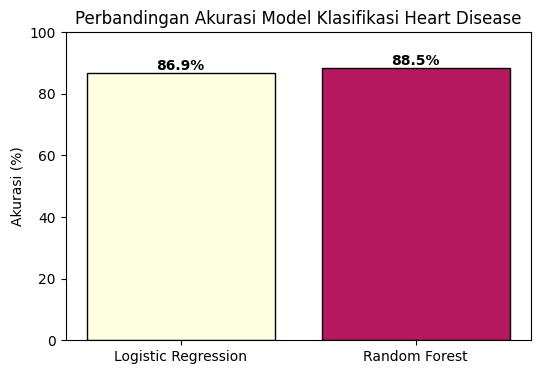

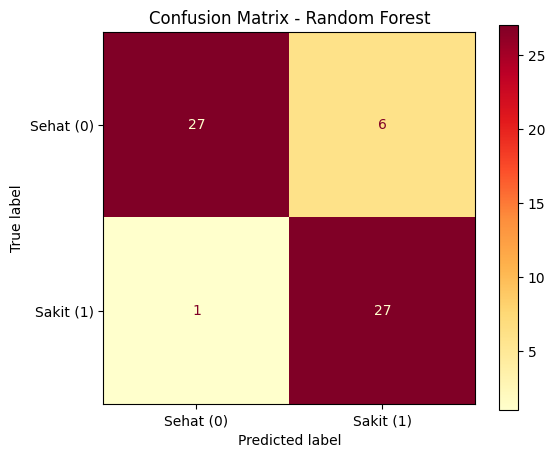

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. VISUALISASI 1: Bar Chart (Akurasi %)
model_names = ['Logistic Regression', 'Random Forest']
accuracies = [accuracy_score(y_test, y_pred_log) * 100, accuracy_score(y_test, y_pred_rf) * 100]

plt.figure(figsize=(6, 4))
bars = plt.bar(model_names, accuracies, color=['#FEFFE0', '#B5185F'], edgecolor='black')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%", ha='center', fontweight='bold')

plt.ylim(0, 100)
plt.ylabel('Akurasi (%)')
plt.title('Perbandingan Akurasi Model Klasifikasi Heart Disease')
plt.show()

# 2. VISUALISASI 2: Confusion Matrix (Jumlah Angka Riil Data)
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sehat (0)', 'Sakit (1)'])

# Ubah warna cmap menjadi 'YlOrRd' (Kuning-Oranye-Merah) atau 'Reds'
disp.plot(cmap=plt.cm.YlOrRd, ax=ax)
plt.title("Confusion Matrix - Random Forest")
plt.show()

Pada tahap evaluasi ini, saya menyajikan dua jenis visualisasi data untuk memberikan gambaran kinerja model secara menyeluruh:

1. Bar Chart (Grafik Batang): "Digunakan untuk memperlihatkan perbandingan performa umum dalam bentuk persentase akurasi antara model Logistic Regression dan Random Forest.

2. Confusion Matrix: "Digunakan untuk melihat performa model Random Forest secara lebih terperinci berdasarkan jumlah angka riil data pasien pada data testing."


*Visualisasi 1: Bar Chart*
1.   Membaca Bar Chart (Perbandingan Akurasi)

> a. Grafik sebelah kiri (Kuning): Model Logistic Regression memperoleh akurasi sebesar 86.9%.   
> b. Grafik sebelah kanan (Merah Tua): Model Random Forest memperoleh akurasi sebesar 88.5%.   
>Kesimpulan Gambar 1: Model Random Forest memiliki tingkat akurasi yang lebih tinggi dibanding Logistic Regression dalam memprediksi risiko penyakit jantung.

*Visualisasi 2: Membaca Confusion Matrix (Data Riil Random Forest)*

Confusion Matrix membandingkan antara Kondisi Asli Pasien (True Label) dengan Hasil Tebakan Model (Predicted Label) pada 61 data uji:

1.   Diagonal Warna Merah Tua (Tebakan Tepat / Akurat):


* 27 Pasien (Kiri Atas): Pasien aslinya Sehat, dan model berhasil menebak dengan benar bahwa mereka Sehat.
* 27 Pasien (Kanan Bawah): Pasien aslinya Sakit, dan model berhasil menebak dengan benar bahwa mereka Sakit.
* Total tebakan yang 100% benar adalah 54 pasien.


2.   Kotak Warna Kuning / Terang (Tebakan Meleset)


*   6 Pasien (Kanan Atas): Pasien aslinya Sehat, namun model salah memprediksi mereka sebagai Sakit (False Positive).
*   Pasien (Kiri Bawah): Pasien aslinya Sakit, namun model terlewat dan memprediksi mereka sebagai Sehat (False Negative).



